# CompBench Debug Samples

Use this notebook to inspect and run one representative annotated sample per CompBench task type. This is a debugging convenience, not the full benchmark inference run. For the complete evaluation, use `compbench_inference.ipynb`.


In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
from PIL import Image
from evaluation.notebook import create_run_directory, load_benchmark
from evaluation.common import annotate_sample, load_sample, run_benchmark, select_reference_prompts

BENCHMARK = "compbench"
RANDOM_SEED = 42
context = load_benchmark(BENCHMARK)
ANNOTATION_FILE = context.annotation_file
OUTPUT_ROOT = context.output_dir
records = context.records
image_loader = context.image_loader
print(f"{len(records)} CompBench annotations loaded from {ANNOTATION_FILE}")
print("Fields:", sorted(records[0]))

2609 CompBench annotations loaded from /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/annotation/compbench/compbench_local_multiobject_mixed.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


CompBench overview: 2609 annotations
add                total= 982  index=   0  add:001ca3cb/0/00003.png  add a gray fish on <v1> with its head downward
remove             total=1331  index= 821  remove:001ca3cb/0/00002.png  remove <v1>
replace            total= 152  index=2145  replace:001ca3cb/0/00010.png  replace <v1> with a black camera long lens
multi_object_add   total=  72  index=2297  multi_object_add:03c21af7_00020.png  add a smaller zebra at <v1> and a bigger zebra at <v2>
multi_object_remove total=  72  index=2327  multi_object_remove:115da184_00002.png  remove <v1> and <v2>


KeyboardInterrupt: 

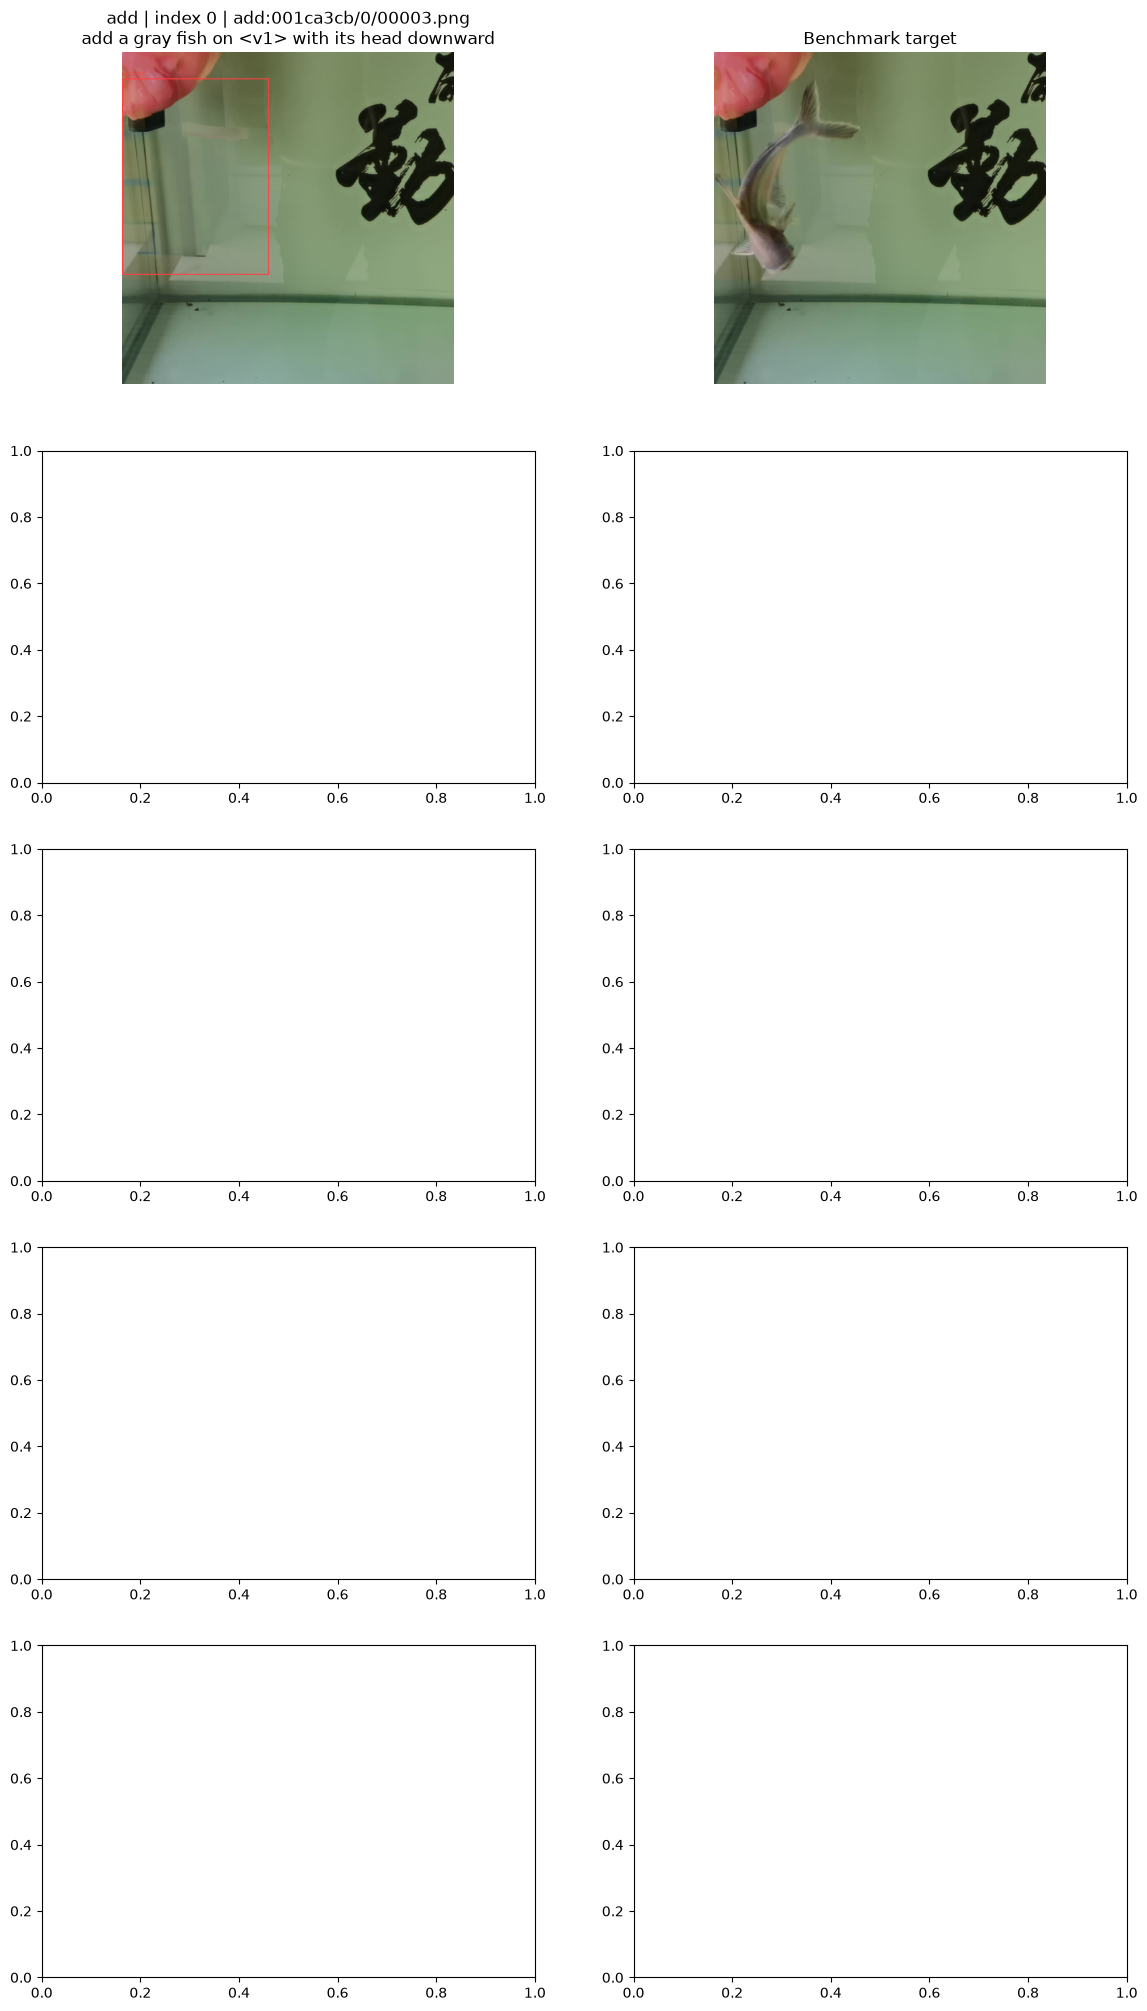

In [2]:
from collections import Counter

TASK_TYPES = ("add", "remove", "replace", "multi_object_add", "multi_object_remove")
task_counts = Counter((record.get("metadata") or {}).get("task") for record in records)
representative_indices = {}

for annotation_index, record in enumerate(records):
    task_type = (record.get("metadata") or {}).get("task")
    if task_type not in TASK_TYPES or task_type in representative_indices:
        continue
    reference_count = len(record.get("references", []))
    if reference_count == 0:
        continue
    if task_type in {"multi_object_add", "multi_object_remove"} and reference_count < 2:
        continue
    representative_indices[task_type] = annotation_index

missing_tasks = set(TASK_TYPES) - representative_indices.keys()
if missing_tasks:
    raise ValueError(f"No representative CompBench samples found for: {sorted(missing_tasks)}")

SAMPLE_INDICES = sorted(representative_indices.values())
print(f"CompBench overview: {len(records)} annotations")
for task_type in TASK_TYPES:
    annotation_index = representative_indices[task_type]
    record = records[annotation_index]
    print(
        f"{task_type:18} total={task_counts[task_type]:4}  index={annotation_index:4}  "
        f"{record['sample_id']}  {record['mixed_instruction']}"
    )

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(14, 5 * len(SAMPLE_INDICES)))
for row, annotation_index in enumerate(SAMPLE_INDICES):
    record = records[annotation_index]
    sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader)
    select_reference_prompts(sample, seed=RANDOM_SEED)
    task_type = (record.get("metadata") or {}).get("task")

    axes[row, 0].imshow(annotate_sample(sample))
    axes[row, 0].set_title(
        f"{task_type} | index {annotation_index} | {record['sample_id']}\n"
        f"{sample['instruction']}"
    )
    axes[row, 0].axis("off")
    if sample["target_image"] is None:
        axes[row, 1].text(0.5, 0.5, "No target image", ha="center", va="center")
    else:
        axes[row, 1].imshow(sample["target_image"])
    axes[row, 1].set_title("Benchmark target")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()
print("Run indices:", SAMPLE_INDICES)

In [ ]:
from framework.tools import image_editing_tools
from evaluation.notebook import create_agent_model

llm = create_agent_model()
tools = image_editing_tools()
print("CompBench agent ready:", llm.model_id)

In [ ]:
# Annotation positions are distinct from the original HF dataset row indices in hf:// references.
# Runs one deterministic representative per CompBench task type.
DEBUG_OUTPUT_DIR = create_run_directory(OUTPUT_ROOT)
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    output_dir=DEBUG_OUTPUT_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    seed=RANDOM_SEED,
    display_fn=None,
)
print('Debug output directory:', DEBUG_OUTPUT_DIR)
print('Per-sample raw steps and trajectory files are included in the results entries.')

In [ ]:
completed = [r for r in benchmark_results if r['status'] == 'completed']
failed = [r for r in benchmark_results if r['status'] == 'failed']
print(f'Debug samples: {len(benchmark_results)} | completed: {len(completed)} | failed: {len(failed)}')
if benchmark_results: print(f"Mean runtime: {sum(r['elapsed_seconds'] for r in benchmark_results)/len(benchmark_results):.2f}s")
print('This debug subset is not a benchmark score.')